# Finding 1: Princeton age and Yelp closure replication

**Question:** Does the time period in which reviews can be accumulated account for the connection between number of reviews and closure?

**Connection to Person 1:** Person 1 studies the Google permanent-closure flag and uses `log2(num_of_reviews)` and Google’s typical `2021-09-30` cutoff. This notebook separately studies the same connection with the Princeton/Yelp is_closed flag and Princeton/Yelp’s dated reviews. We use a common `2021-09-30` cutoff for a more comparable observation period, and report a separate sensitivity using Princeton's latest review date. Samples, databases, closure flags, and counts differ, so the estimated associations are not directly comparable.

**Outputs:** Age distribution by restaurant, coverage audit, odds ratios with 95% CIs, sparse review sensitivity, comparison graph, and draft handover file. Execute cells from top to bottom. No archives from Person 1's Google data are needed.

## 1. Imports, paths, and cutoff

In [66]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

repo = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data/processed_princeton_chicago/businesses.parquet").exists()),
    None,
)
if repo is None:
    raise FileNotFoundError('Open notebook from inside CS418_Economic_Trajectories_Group')
source_dir = repo / "data" / "processed_princeton_chicago"
out = repo / 'person2_results'
out.mkdir(exist_ok=True)
GOOGLE_CUTOFF = pd.Timestamp('2021-09-30')
print('Project:', repo)
print('Output:', out)

Project: g:\My Drive\CS-418 Economics Group\Project_repo\CS418_Economic_Trajectories_Group
Output: g:\My Drive\CS-418 Economics Group\Project_repo\CS418_Economic_Trajectories_Group\person2_results


## 2. Load and audit Princeton businesses and dated reviews

Within-window volume shall be the number of reviews that actually exist on that date. The value for Princeton’s `is_closed` is just a snapshot and not an actual closing of the establishment on the cut-off date.

In [67]:
businesses = pd.read_parquet(source_dir / 'businesses.parquet')
reviews = pd.read_parquet(source_dir / 'reviews.parquet', columns=['business_id', 'date'])
assert {'business_id', 'is_closed'}.issubset(businesses.columns)
assert businesses['business_id'].notna().all() and businesses['business_id'].is_unique
raw_date = reviews['date'].astype('string').str.extract(r'^(\d{1,2}/\d{1,2}/\d{4})', expand=False)
reviews['review_date'] = pd.to_datetime(raw_date, format='%m/%d/%Y', errors='coerce')
latest_review = reviews['review_date'].max()
print('Businesses:', len(businesses), '| Review rows:', len(reviews))
print('Valid review dates:', reviews['review_date'].notna().sum(), '| Latest:', latest_review.date())
print('is_closed values:', businesses['is_closed'].value_counts(dropna=False).to_dict())

Businesses: 5355 | Review rows: 1331020
Valid review dates: 1331020 | Latest: 2021-11-07
is_closed values: {False: 5323, True: 32}


## 3. Construct one row per restaurant

**Observed review age at the cutoff** is the time between the first recorded review and the common cutoff date. This approximates how long a business has been observable in the review data. Actual opening dates and operating duration remain unverified.

In [68]:
def make_table(cutoff):
    eligible = reviews.loc[reviews['review_date'].notna() & reviews['review_date'].le(cutoff)]
    summary = eligible.groupby('business_id').agg(
        dated_review_count=('review_date','size'),
        first_review_date=('review_date','min'),
        last_review_date=('review_date','max'))
    frame = businesses.merge(summary, left_on='business_id', right_index=True, how='left', validate='one_to_one')
    frame['dated_review_count'] = frame['dated_review_count'].fillna(0).astype(int)
    frame['age_at_cutoff_years'] = (cutoff - frame['first_review_date']).dt.days / 365.25
    frame['log2_reviews'] = np.log2(1 + frame['dated_review_count'])
    closed = pd.to_numeric(frame['is_closed'], errors='coerce')
    frame['closure'] = closed.where(closed.isin([0,1]))
    return frame, len(eligible)

restaurants, n_dated = make_table(GOOGLE_CUTOFF)
restaurants.to_csv(out / 'restaurant_age_table.csv', index=False)
assert restaurants['business_id'].is_unique
coverage = pd.DataFrame([{
    'cutoff': str(GOOGLE_CUTOFF.date()),
    'all_businesses': len(restaurants),
    'known_yelp_status': restaurants['closure'].notna().sum(),
    'with_dated_reviews': restaurants['first_review_date'].notna().sum(),
    'status_and_age': restaurants[['closure','age_at_cutoff_years']].notna().all(axis=1).sum(),
    'closed_in_age_sample': restaurants.loc[restaurants['age_at_cutoff_years'].notna(),'closure'].sum(),
    'dated_review_rows_before_cutoff': n_dated
}])
coverage.to_csv(out / 'coverage.csv', index=False)
display(coverage)
display(restaurants[['business_id','dated_review_count','closure','first_review_date','last_review_date','age_at_cutoff_years']].head())

,cutoff,all_businesses,known_yelp_status,with_dated_reviews,status_and_age,closed_in_age_sample,dated_review_rows_before_cutoff
0,2021-09-30,5355,5355,4984,4984,32,1330681


,business_id,dated_review_count,closure,first_review_date,last_review_date,age_at_cutoff_years
0,--Yw337vTC4fLKRCaw-PLQ,189,False,2018-10-28,2021-09-27,2.924025
1,--li1INYTksr8rYmhP_wqQ,69,False,2014-06-23,2021-08-16,7.271732
2,-0jSje0DiHQj7GvO_JrHVg,94,False,2018-05-09,2021-09-16,3.394935
3,-1N2SDvOKHrdGPhaPObTFA,120,False,2019-05-18,2021-09-30,2.370979
4,-22GoLdX0clVOi-LVUJF6w,259,False,2005-08-27,2021-08-04,16.093087


## 4. Logistic regression and 95% confidence intervals

Model: `logit(P(Yelp is_closed=1)) = intercept + β × log2(1 + dated review count) + age proxy`. The odds ratio below is an estimate of a one unit change in log2(1 + reviews), or roughly double `1 + reviews`. Robust standard errors are based on HC1 and we have used the same age-observed sample for the baseline and adjusted models. Given few closed restaurants, the intervals may be quite large.

In [69]:
model_rows = []
def fit_model(label, frame, predictors, cutoff_label='2021-09-30'):
    use = frame[['closure'] + predictors].dropna().copy()
    if len(use) < 10 or use['closure'].nunique() < 2:
        print('Skipped:', label, '(insufficient outcome variation)'); return
    X = sm.add_constant(use[predictors].astype(float), has_constant='add')
    try:
        fit = sm.GLM(use['closure'].astype(float), X, family=sm.families.Binomial()).fit(cov_type='HC1')
    except Exception as exc:
        print('Skipped:', label, exc); return
    ci = fit.conf_int()
    for term in predictors:
        model_rows.append(dict(cutoff=cutoff_label, model=label, predictor=term,
            n=len(use), closed_n=int(use['closure'].sum()), coefficient=fit.params[term],
            odds_ratio=np.exp(fit.params[term]), ci_low=np.exp(ci.loc[term,0]),
            ci_high=np.exp(ci.loc[term,1]), p_value=fit.pvalues[term]))

usable = restaurants.dropna(subset=['closure','age_at_cutoff_years'])
fit_model('All known-status restaurants: volume only', restaurants, ['log2_reviews'])
fit_model('Same sample: volume only', usable, ['log2_reviews'])
fit_model('Adjusted: age at common cutoff', usable, ['log2_reviews','age_at_cutoff_years'])
models = pd.DataFrame(model_rows)
display(models.loc[models.predictor.eq('log2_reviews')].round(3))

,cutoff,model,predictor,n,closed_n,coefficient,odds_ratio,ci_low,ci_high,p_value
0,2021-09-30,All known-status restaurants: volume only,log2_reviews,5355,32,0.304,1.355,1.152,1.593,0.000
1,2021-09-30,Same sample: volume only,log2_reviews,4984,32,0.288,1.334,1.117,1.593,0.001
2,2021-09-30,Adjusted: age at common cutoff,log2_reviews,4984,32,0.161,1.174,0.969,1.424,0.102


## 5. Sparse-review and cutoff sensitivity

Use restaurants with at least 5, 10, or 20 dated reviews and repeat the age-at-cutoff adjustment. Also rerun the models using the most recent Princeton review date. This later cutoff is a sensitivity check with a different observation window.

In [70]:
for minimum in (5,10,20):
    subset = usable.loc[usable['dated_review_count'] >= minimum]
    fit_model(f'At least {minimum} dated reviews: cutoff age', subset, ['log2_reviews','age_at_cutoff_years'])

if latest_review > GOOGLE_CUTOFF:
    later, later_count = make_table(latest_review)
    later_usable = later.dropna(subset=['closure','age_at_cutoff_years'])
    fit_model('Latest Princeton cutoff: volume only', later_usable, ['log2_reviews'], str(latest_review.date()))
    fit_model('Latest Princeton cutoff: cutoff age', later_usable, ['log2_reviews','age_at_cutoff_years'], str(latest_review.date()))

models = pd.DataFrame(model_rows)
models.to_csv(out / 'model_comparison.csv', index=False)
volume = models.loc[models['predictor'].eq('log2_reviews')].copy()
display(volume[['cutoff','model','n','closed_n','odds_ratio','ci_low','ci_high','p_value']].round(3))

,cutoff,model,n,closed_n,odds_ratio,ci_low,ci_high,p_value
0,2021-09-30,All known-status restaurants: volume only,5355,32,1.355,1.152,1.593,0.000
1,2021-09-30,Same sample: volume only,4984,32,1.334,1.117,1.593,0.001
2,2021-09-30,Adjusted: age at common cutoff,4984,32,1.174,0.969,1.424,0.102
4,2021-09-30,At least 5 dated reviews: cutoff age,4613,32,1.136,0.908,1.422,0.264
6,2021-09-30,At least 10 dated reviews: cutoff age,4351,31,1.167,0.926,1.471,0.191
8,2021-09-30,At least 20 dated reviews: cutoff age,3991,30,1.176,0.914,1.513,0.209
10,2021-11-07,Latest Princeton cutoff: volume only,4984,32,1.334,1.117,1.593,0.001
11,2021-11-07,Latest Princeton cutoff: cutoff age,4984,32,1.174,0.969,1.423,0.102


## 6. Figure effect sizes and uncertainty

Title states the takeaway conditionally: the plot reports odds ratios and 95% confidence intervals, not a causal effect. The vertical reference line is OR = 1.

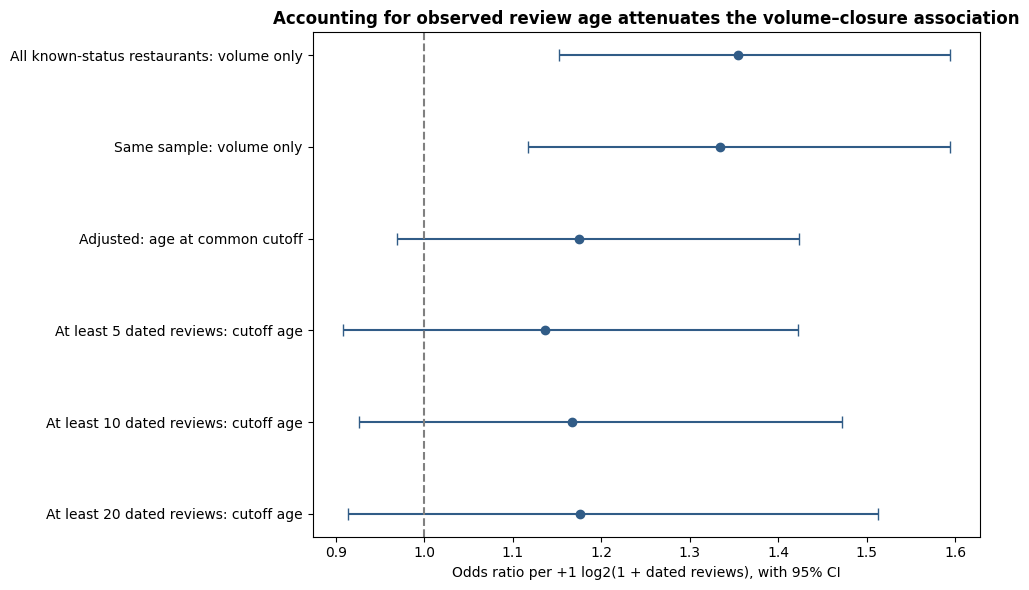

In [71]:
main = volume.loc[volume['cutoff'].eq(str(GOOGLE_CUTOFF.date()))].copy()
base = main.loc[main['model'].eq('Same sample: volume only')].iloc[0]
age = main.loc[main['model'].eq('Adjusted: age at common cutoff')].iloc[0]
title = ('Accounting for observed review age attenuates the volume–closure association'
         if abs(np.log(age.odds_ratio)) < abs(np.log(base.odds_ratio))
         else 'Review-volume association changes after observed-age adjustment')
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(main))
ax.errorbar(main['odds_ratio'], y,
            xerr=[main['odds_ratio']-main['ci_low'],main['ci_high']-main['odds_ratio']],
            fmt='o', capsize=4, color='#315c87')
ax.axvline(1, linestyle='--', color='gray')
ax.set_yticks(y, main['model'])
ax.invert_yaxis()
ax.set_xlabel('Odds ratio per +1 log2(1 + dated reviews), with 95% CI')
ax.set_title(title, fontsize=12, weight='bold')
fig.tight_layout()
fig.savefig(out / 'person2_review_volume_age_checks.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Age and Replication Check Findings

The pooled Princeton sample contains 5,355 restaurants, of which 4,984 have dated reviews and 32 are marked closed. On the same 4,984 restaurants, the review-count odds ratio falls from 1.334 (95% interval 1.117–1.593) to 1.174 (0.969–1.424) after adjusting for observed review age at the common cutoff. The age-adjusted interval includes no association. These estimates describe a mixture of CHI, UDIS, and EYG collections. The EYG investigation below recovers consistently sourced flags and counts for the historical EYG cohort and supplies the current narrative.

## EYG investigation

Can the Eight Year Gap cohort support an analysis of review volume and closure status using flags from a common source? The target is all 123 EYG-linked Chicago restaurants, including the 91 also present in CHI.

The processing script gives CHI metadata precedence over EYG for overlaps. We recover EYG's own business records before defining the open and closed groups. A retained CHI flag supplies a comparison value. It cannot fill a missing EYG flag.

This section records which sources were actually read, audits timing, and reports a group comparison only when EYG's own flags and counts are accessible. Its conclusions qualify the earlier pooled regressions.

In [72]:
from pathlib import Path
import hashlib
import json
import os
import zipfile

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

eyg_repo = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data/processed_princeton_chicago/businesses.parquet").is_file()),
    None,
)
if eyg_repo is None:
    raise FileNotFoundError("Run inside the project containing data/processed_princeton_chicago.")
eyg_processed_dir = eyg_repo / "data/processed_princeton_chicago"
eyg_businesses = pd.read_parquet(eyg_processed_dir / "businesses.parquet")
eyg_linked = eyg_businesses.loc[
    eyg_businesses["source_partitions"].map(lambda parts: "EYG" in parts)
].copy()
assert eyg_linked["business_id"].is_unique
eyg_target_ids = set(eyg_linked["business_id"])
eyg_linked["has_chi"] = eyg_linked["source_partitions"].map(lambda parts: "CHI" in parts)
eyg_linked["retained_source"] = eyg_linked["source_partitions"].map(
    lambda parts: next(source for source in ("CHI", "UDIS", "EYG") if source in parts)
)
eyg_linked["membership"] = eyg_linked["has_chi"].map(
    {True: "EYG and CHI", False: "EYG without CHI"}
)
display(
    eyg_linked.groupby(["membership", "retained_source"], dropna=False)["is_closed"]
    .agg(restaurants="size", retained_closed="sum")
)
print(f"Target EYG-linked restaurants: {len(eyg_linked)}")
print("Retained flags are shown for the provenance audit only.")

,,restaurants,retained_closed
membership,retained_source,,
EYG and CHI,CHI,91,0
EYG without CHI,EYG,32,32


Target EYG-linked restaurants: 123
Retained flags are shown for the provenance audit only.


### 1 Recover the original EYG flags

The original member is **data_release/data/eyg_data/businessid_to_data.json** inside **data/longitudinal_reviews_2022-05-25-1444.zip**. The published format identifies it as Yelp Fusion API business output. The local processing script reads this member, then overwrites overlapping business metadata with CHI records.

Run the EYG investigation cells in order. The next cell accepts an extracted original eyg_data directory or the existing archive. For an encrypted archive, **EYG_PROMPT_FOR_PASSWORD = True** enables a hidden password prompt by default. Enter the original dataset archive password once; it is reused in kernel memory for the metadata and both review files. You can alternatively supply the **PRINCETON_ZIP_PASSWORD** environment variable. The credential is not written to notebook outputs or data files. Decrypting the review files can take a few minutes. Before fitting models, confirm **EYG metadata access: original metadata read** and **original read** for both review files. [Dataset structure](https://sites.google.com/princeton.edu/longitudinal-review-data/structure)

In [73]:
# Optional directory containing the original businessid_to_data.json and review JSON files.
EYG_ORIGINAL_DIRECTORY = None
EYG_PROMPT_FOR_PASSWORD = True
_eyg_archive_password = os.environ.get("PRINCETON_ZIP_PASSWORD")

eyg_archive_path = eyg_repo / "data/longitudinal_reviews_2022-05-25-1444.zip"
eyg_member_prefix = "data_release/data/eyg_data/"
eyg_archive_inventory = []
if eyg_archive_path.is_file():
    with zipfile.ZipFile(eyg_archive_path) as archive:
        for member in archive.infolist():
            if member.filename.startswith(eyg_member_prefix) and not member.is_dir():
                eyg_archive_inventory.append({
                    "member": member.filename,
                    "bytes_uncompressed": member.file_size,
                    "password_encrypted": bool(member.flag_bits & 1),
                    "zip_file_timestamp": "-".join(map(str, member.date_time[:3])),
                })
display(pd.DataFrame(eyg_archive_inventory))

def eyg_read_original(filename):
    global _eyg_archive_password
    if EYG_ORIGINAL_DIRECTORY is not None:
        path = Path(EYG_ORIGINAL_DIRECTORY) / filename
        return path.read_bytes(), f"Original extraction / {filename}"
    if not eyg_archive_path.is_file():
        raise FileNotFoundError("Original Princeton archive is missing.")
    with zipfile.ZipFile(eyg_archive_path) as archive:
        member = archive.getinfo(eyg_member_prefix + filename)
        if member.flag_bits & 1 and not _eyg_archive_password:
            if not EYG_PROMPT_FOR_PASSWORD:
                raise PermissionError(
                    "Archive password missing. Set EYG_PROMPT_FOR_PASSWORD = True and rerun this cell."
                )
            from getpass import getpass
            _eyg_archive_password = getpass("Princeton archive password (hidden): ")
            if not _eyg_archive_password:
                raise PermissionError("No archive password entered. Rerun this cell to try again.")
        try:
            payload = archive.read(
                member, pwd=_eyg_archive_password.encode() if _eyg_archive_password else None
            )
        except RuntimeError:
            _eyg_archive_password = None
            raise PermissionError(
                "Archive password was not accepted. Rerun this cell and enter the dataset archive password."
            ) from None
    return payload, member.filename

eyg_raw_metadata = None
eyg_metadata_access = "unavailable"
eyg_metadata_origin = None
eyg_metadata_sha256 = None
try:
    payload, eyg_metadata_origin = eyg_read_original("businessid_to_data.json")
    eyg_metadata_sha256 = hashlib.sha256(payload).hexdigest()
    eyg_raw_metadata = json.loads(payload)
    if not isinstance(eyg_raw_metadata, list):
        raise ValueError("Unexpected original EYG metadata structure. Inspect before using.")
    del payload
    eyg_metadata_access = "original metadata read"
except (PermissionError, FileNotFoundError, KeyError) as exc:
    eyg_metadata_access = str(exc)

print("EYG metadata access:", eyg_metadata_access)
if eyg_raw_metadata is not None:
    print("Original member:", eyg_metadata_origin)
    print("Original member SHA256:", eyg_metadata_sha256)
    print("Business records in the original EYG file:", len(eyg_raw_metadata))
else:
    print(
        "Missing evidence: EYG's own is_closed and review_count values for all target IDs, "
        "including the 91 CHI overlaps. No EYG open/closed groups have been assigned."
    )

,member,bytes_uncompressed,password_encrypted,zip_file_timestamp
0,data_release/data/eyg_data/businessid_to_data....,349387,True,2022-1-6
1,data_release/data/eyg_data/not_recommended_rev...,15312676,True,2022-1-6
2,data_release/data/eyg_data/recommended_reviews...,172878067,True,2022-1-6


EYG metadata access: original metadata read
Original member: data_release/data/eyg_data/businessid_to_data.json
Original member SHA256: d7a1ea7f20fcfa48aac38e5c16fae35630edf62a7e988296c5ff824c26a14849
Business records in the original EYG file: 201


In [74]:
eyg_recovered = None
eyg_complete_source = False
if eyg_raw_metadata is not None:
    source_rows = [
        {"business_id": row["id"], "eyg_is_closed_raw": row.get("is_closed"),
         "eyg_review_count_raw": row.get("review_count")}
        for row in eyg_raw_metadata if row.get("id") in eyg_target_ids
    ]
    source_frame = pd.DataFrame(source_rows)
    if source_frame.empty or source_frame["business_id"].duplicated().any():
        raise ValueError("Original EYG target IDs are absent or duplicated. Inspect before joining.")
    eyg_recovered = eyg_linked[
        ["business_id", "is_closed", "retained_source", "has_chi"]
    ].rename(columns={"is_closed": "retained_is_closed"}).merge(
        source_frame, on="business_id", how="left", validate="one_to_one", indicator=True
    )
    valid_flags = eyg_recovered["eyg_is_closed_raw"].map(
        lambda value: isinstance(value, (bool, np.bool_))
    )
    eyg_recovered["eyg_is_closed"] = pd.Series(pd.NA, index=eyg_recovered.index, dtype="boolean")
    eyg_recovered.loc[valid_flags, "eyg_is_closed"] = (
        eyg_recovered.loc[valid_flags, "eyg_is_closed_raw"].astype(bool).to_numpy()
    )
    eyg_recovered["eyg_review_count"] = pd.to_numeric(
        eyg_recovered["eyg_review_count_raw"], errors="coerce"
    )
    eyg_recovered.loc[
        ~eyg_recovered["eyg_review_count"].ge(0)
        | ~np.isfinite(eyg_recovered["eyg_review_count"]), "eyg_review_count"
    ] = np.nan
    eyg_complete_source = bool(
        eyg_recovered["_merge"].eq("both").all()
        and eyg_recovered["eyg_is_closed"].notna().all()
    )
    print("Target IDs recovered:", int(eyg_recovered["_merge"].eq("both").sum()), "/", len(eyg_linked))
    print("Target IDs with verified boolean EYG flags:", int(valid_flags.sum()))
    display(eyg_recovered.groupby("has_chi", dropna=False)["eyg_is_closed"].value_counts(dropna=False))
    paired = eyg_recovered.loc[eyg_recovered["has_chi"] & eyg_recovered["eyg_is_closed"].notna()]
    print("Original EYG versus retained CHI flags for overlapping IDs")
    display(pd.crosstab(
        paired["eyg_is_closed"], paired["retained_is_closed"],
        rownames=["Original EYG closed"], colnames=["Retained CHI closed"], dropna=False,
    ))
    print("Flag disagreements:", int(
        paired["eyg_is_closed"].astype(bool).ne(paired["retained_is_closed"].astype(bool)).sum()
    ))
else:
    display(Markdown(
        "**Recovery blocked.** The 32 EYG-only rows retain EYG-sourced metadata, but the "
        "91 overlaps retain CHI metadata. EYG closure statuses for those overlaps remain "
        "unknown until the original member is opened."
    ))

Target IDs recovered: 123 / 123
Target IDs with verified boolean EYG flags: 123


has_chi  eyg_is_closed
False    True             32
True     False            91
Name: count, dtype: Int64

Original EYG versus retained CHI flags for overlapping IDs


Retained CHI closed,False
Original EYG closed,
False,91


Flag disagreements: 0


### 2 Establish collection timing

**Verified documentation.** The authors revisited a business sample established in 2012 for EYG in **2020**. They obtained business metadata through Yelp's Fusion API during setup, then crawled reviews from the selected businesses. These sources give the study year and collection order. Exact per-business observation dates need metadata timestamps or collection logs. [Study methods, Sections 3.2 and 3.3](https://arxiv.org/html/2202.09005v1#S3)

**File evidence.** The archive inventory reports January 6, 2022 for the EYG files. That timestamp describes the stored files and does not establish when Yelp status was observed. The ZIP filename's 2022 date also cannot date a closure.

**Exposure definition.** The comparison uses EYG's review_count and is_closed from the same recovered original business record. The original EYG review files include posts through August 8, 2020, and contain histories for 121 of the 123 target restaurants. Exact metadata observation dates remain unknown. Counts reconstructed from the combined Parquet histories include later CHI reviews through October 2021 and cannot automatically be paired with a 2020 EYG flag.

In [75]:
eyg_review_records = pd.read_parquet(
    eyg_processed_dir / "reviews.parquet", columns=["business_id", "date", "source_partition"]
)
eyg_review_records = eyg_review_records.loc[
    eyg_review_records["business_id"].isin(eyg_target_ids)
].copy()
date_text = eyg_review_records["date"].astype("string").str.extract(
    r"^(\d{1,2}/\d{1,2}/\d{4})", expand=False
)
eyg_review_records["review_date"] = pd.to_datetime(
    date_text, format="%m/%d/%Y", errors="coerce"
)
print("Dated reviews retained in the combined extract for EYG-linked restaurants")
display(eyg_review_records.groupby("source_partition").agg(
    retained_rows=("business_id", "size"),
    restaurants=("business_id", "nunique"),
    first_post=("review_date", "min"),
    last_post=("review_date", "max"),
))
print(
    "These are posting dates. Source_partition=EYG contains rows retained after "
    "CHI-first deduplication and may omit EYG reviews duplicated in CHI."
)
if eyg_raw_metadata is not None:
    timestamp_fields = sorted({
        key for row in eyg_raw_metadata for key in row
        if any(word in key.lower() for word in ("timestamp", "collected", "crawled", "created_at", "updated_at"))
    })
    print("Candidate observation-timestamp fields in original metadata:", timestamp_fields)
    if not timestamp_fields:
        print("No obvious observation-timestamp field found in the original business records.")
    print("Any candidate timestamp still requires verification as a status observation date.")

Dated reviews retained in the combined extract for EYG-linked restaurants


,retained_rows,restaurants,first_post,last_post
source_partition,,,,
CHI-9,152632,89,2004-10-12,2021-10-06
EYG,24694,121,2004-11-24,2020-08-01


These are posting dates. Source_partition=EYG contains rows retained after CHI-first deduplication and may omit EYG reviews duplicated in CHI.
Candidate observation-timestamp fields in original metadata: []
No obvious observation-timestamp field found in the original business records.
Any candidate timestamp still requires verification as a status observation date.


### 3 Compare consistently sourced review counts

When all target EYG flags are recovered, show the number of restaurants and the quartiles, median, and range of EYG's original metadata review count in each status group. The effect estimate is **median reviews among closed restaurants minus median reviews among open restaurants**.

For uncertainty, resample restaurants independently within each status group 10,000 times with seed 418 and report a percentile 95% interval for the median difference. At least two observations in each group are needed for this resampling calculation. Also report the probability that a randomly selected closed restaurant has more reviews than an open one, counting ties as one half. The bootstrap describes variation within this selected cohort and does not correct its historical selection.

In [76]:
eyg_comparison = None
eyg_effect = None
if eyg_complete_source:
    eyg_comparison = eyg_recovered.dropna(subset=["eyg_review_count"]).copy()
    print("Excluded for unusable original EYG review count:", len(eyg_recovered) - len(eyg_comparison))
    eyg_comparison["status"] = eyg_comparison["eyg_is_closed"].map(
        {False: "Open flag", True: "Closed flag"}
    )
    display(eyg_comparison.groupby("status")["eyg_review_count"].agg(
        restaurants="size", minimum="min", q1=lambda x: x.quantile(0.25),
        median="median", q3=lambda x: x.quantile(0.75), maximum="max",
    ))
    open_counts = eyg_comparison.loc[
        ~eyg_comparison["eyg_is_closed"].astype(bool), "eyg_review_count"
    ].to_numpy(dtype=float)
    closed_counts = eyg_comparison.loc[
        eyg_comparison["eyg_is_closed"].astype(bool), "eyg_review_count"
    ].to_numpy(dtype=float)
    if min(len(open_counts), len(closed_counts)) >= 2:
        rng = np.random.default_rng(418)
        closed_boot = np.median(rng.choice(closed_counts, (10000, len(closed_counts))), axis=1)
        open_boot = np.median(rng.choice(open_counts, (10000, len(open_counts))), axis=1)
        differences = closed_boot - open_boot
        eyg_effect = {
            "open_n": len(open_counts), "closed_n": len(closed_counts),
            "median_closed_minus_open": float(np.median(closed_counts) - np.median(open_counts)),
            "lower": float(np.quantile(differences, 0.025)),
            "upper": float(np.quantile(differences, 0.975)),
            "probability_closed_more": float(
                np.mean(closed_counts[:, None] > open_counts[None, :])
                + 0.5 * np.mean(closed_counts[:, None] == open_counts[None, :])
            ),
        }
        display(pd.DataFrame([eyg_effect]).round(3))
        print("Negative median difference means the closed-flag group has fewer accumulated reviews.")
        print("The interval is a conditional bootstrap interval for this selected cohort.")
    else:
        print("Too little within-group information for a two-group bootstrap estimate.")
else:
    display(Markdown(
        "**Comparison pending original EYG metadata.** No common-source EYG group medians, "
        "effect estimate, or confidence interval can be computed from the retained flags alone."
    ))

Excluded for unusable original EYG review count: 0


,restaurants,minimum,q1,median,q3,maximum
status,,,,,,
Closed flag,32,8.0,45.0,398.0,658.5,3127.0
Open flag,91,47.0,738.0,1247.0,2086.5,7157.0


,open_n,closed_n,median_closed_minus_open,lower,upper,probability_closed_more
0,91,32,-849.0,-1195.012,-545.975,0.166


Negative median difference means the closed-flag group has fewer accumulated reviews.
The interval is a conditional bootstrap interval for this selected cohort.


### 4 Check temporal order and accumulation time

EYG's metadata review count and closure flag describe a record retrieved together. This supplies a snapshot association. Establishing that review volume preceded the status observation requires an earlier dated count or reviews restricted to a verified earlier cutoff. Even then, the source must establish that each restaurant was open at baseline and identify a later outcome observation.

An individual review's posting date supplies no closure date. Reviews can be written after a visit and after a business closes. The first review only approximates the beginning of observed activity, and the final review only marks the end of observed review activity. Using September 2021 reviews with an EYG status documented only at study-year level in 2020 can introduce information from after the status observation.

The original EYG review files can bound the review collection window, subject to posting-date validity. Their latest posting date gives a lower bound on when those reviews were obtained, but exact status observation dates still require additional evidence. The next cell audits those original files if accessible. It keeps EYG review histories separate from CHI and deduplicates on business ID, date, rating, and review text, following the project's existing signature rule.

In [77]:
eyg_original_review_audit = []
eyg_original_histories = None
if eyg_raw_metadata is not None:
    eyg_unique_reviews = {}
    for review_file in ("recommended_reviews.json", "not_recommended_reviews.json"):
        try:
            raw_bytes, origin = eyg_read_original(review_file)
            groups = json.loads(raw_bytes)
            del raw_bytes
        except (PermissionError, FileNotFoundError, KeyError) as exc:
            eyg_original_review_audit.append({"file": review_file, "access": str(exc)})
            continue
        if not isinstance(groups, dict):
            raise ValueError("Unexpected original review layout; inspect before using.")
        dates = []
        target_rows = 0
        for business_id, rows in groups.items():
            if business_id not in eyg_target_ids:
                continue
            for row in rows:
                target_rows += 1
                dates.append(row.get("date"))
                signature = json.dumps(
                    [business_id, row.get("date"), row.get("rating"), row.get("content")],
                    ensure_ascii=False, separators=(",", ":"),
                ).encode("utf-8")
                eyg_unique_reviews.setdefault(hashlib.sha256(signature).hexdigest(), {
                    "business_id": business_id, "date": row.get("date"), "rating": row.get("rating"),
                })
        parsed = pd.to_datetime(
            pd.Series(dates, dtype="string").str.extract(
                r"^(\d{1,2}/\d{1,2}/\d{4})", expand=False
            ), format="%m/%d/%Y", errors="coerce",
        )
        eyg_original_review_audit.append({
            "file": review_file, "access": "original read", "target_review_rows": target_rows,
            "unparsed_dates": int(parsed.isna().sum()),
            "first_post": parsed.min(), "last_post": parsed.max(),
        })
    display(pd.DataFrame(eyg_original_review_audit))
    if eyg_unique_reviews:
        history = pd.DataFrame(eyg_unique_reviews.values())
        history["review_date"] = pd.to_datetime(
            history["date"].astype("string").str.extract(r"^(\d{1,2}/\d{1,2}/\d{4})", expand=False),
            format="%m/%d/%Y", errors="coerce",
        )
        eyg_original_histories = history.groupby("business_id").agg(
            unique_eyg_reviews=("date", "size"),
            first_eyg_review=("review_date", "min"), last_eyg_review=("review_date", "max"),
        )
        print("Original EYG restaurant histories recovered:", len(eyg_original_histories))
        print("A missing history or failed review-file read cannot be interpreted as zero reviews.")
else:
    print("Original EYG review posting-date audit also requires the archive password or original extraction.")

,file,access,target_review_rows,unparsed_dates,first_post,last_post
0,recommended_reviews.json,original read,143920,0,2004-11-24,2020-08-08
1,not_recommended_reviews.json,original read,18696,0,2004-10-12,2020-08-05


Original EYG restaurant histories recovered: 121
A missing history or failed review-file read cannot be interpreted as zero reviews.


### 5 Adjust the EYG association

We follow Person 1's sequence with four restaurant-level logistic models on the **same complete EYG cohort**. Model 1 uses original EYG review count, Model 2 adds observed review age, Model 3 adds original Yelp rating and negative-rating share, and Model 4 adds community area.

All EYG flags, metadata review counts, ratings, coordinates, and review-based controls come from the original EYG files. Negative share is the fraction of dated original EYG ratings at 1 or 2 stars, including recommended and not-recommended reviews. Age is time since the first original EYG review to the latest review date in the cohort. That common reference date anchors an activity-history proxy, while the metadata observation date remains unknown.

With 32 closed cases, we keep the restaurant controls modest. Category, chain status, and citywide competition are omitted from these models. EYG does not enumerate all Chicago competitors at a common date. Consequently, the covariate sets differ from Person 1's larger Google analysis.

Use ridge logistic regression with an unpenalized intercept and L2 penalty of 1 on standardized slopes and community-area coefficients. Regularization keeps sparse area estimates finite. Continuous predictors are standardized on the common cohort, and that scaling is held fixed in the bootstrap. Sensitivity checks use penalties 0.5 and 2. The penalty is part of the estimator and all four fits use the same convention. [Penalized binomial model definition](https://www.statsmodels.org/v0.14.4/generated/statsmodels.genmod.generalized_linear_model.GLM.fit_regularized.html)

In [78]:
if eyg_raw_metadata is None or eyg_original_histories is None:
    raise RuntimeError(
        "Original EYG data were not loaded. Rerun the EYG investigation cells from "
        "'1 Recover the original EYG flags' through '4 Check temporal order and accumulation time', "
        "enter the archive password at the hidden prompt, and confirm both review files report "
        "'original read' before rerunning the model cells."
    )
if not all(row.get("access") == "original read" for row in eyg_original_review_audit):
    raise RuntimeError("Both original EYG review files are required for model controls.")

model_history = pd.DataFrame(eyg_unique_reviews.values())
model_history["parsed_date"] = pd.to_datetime(
    model_history["date"].astype("string").str.extract(r"^(\d{1,2}/\d{1,2}/\d{4})", expand=False),
    format="%m/%d/%Y", errors="coerce",
)
model_history["rating"] = pd.to_numeric(model_history["rating"], errors="coerce")
model_history["valid_rating"] = model_history["parsed_date"].notna() & model_history["rating"].between(1, 5)
history_controls = []
for business_id, records in model_history.groupby("business_id"):
    rated = records.loc[records["valid_rating"], "rating"]
    history_controls.append({
        "business_id": business_id,
        "first_review": records["parsed_date"].min(),
        "last_review": records["parsed_date"].max(),
        "dated_review_count": len(rated),
        "negative_share": rated.le(2).mean() if len(rated) else np.nan,
    })
source_controls = []
for business in eyg_raw_metadata:
    if business["id"] in eyg_target_ids:
        coordinates = business.get("coordinates") or {}
        source_controls.append({
            "business_id": business["id"], "closed": int(business["is_closed"]),
            "review_count": business.get("review_count"),
            "rating": business.get("rating"),
            "latitude": coordinates.get("latitude"), "longitude": coordinates.get("longitude"),
        })
eyg_model_features = pd.DataFrame(source_controls).merge(
    pd.DataFrame(history_controls), on="business_id", how="left", validate="one_to_one"
)
assert len(eyg_model_features) == len(eyg_target_ids) and eyg_model_features["business_id"].is_unique

Assign community areas by testing the **original EYG coordinates** against the City of Chicago's published polygons. Cache the GeoJSON in the project data directory for reruns. These are current boundaries used as geographic labels for historical locations. Their applicability to 2020 is an assumption, and they supply no historical demographic measures. Retain every complete restaurant, including those in areas with a single observed status, with area coefficients regularized in Model 4. [Chicago community-area boundaries](https://data.cityofchicago.org/d/igwz-8jzy)

In [79]:
from urllib.request import urlopen
from matplotlib.path import Path as PolygonPath

geo_path = eyg_repo / "data/finding_1/chicago_community_areas.geojson"
if not geo_path.exists():
    geo_path.parent.mkdir(exist_ok=True)
    with urlopen("https://data.cityofchicago.org/resource/igwz-8jzy.geojson?$limit=100", timeout=60) as response:
        geojson = json.load(response)
    temporary = geo_path.with_suffix(".tmp")
    temporary.write_text(json.dumps(geojson), encoding="utf-8")
    temporary.replace(geo_path)
else:
    geojson = json.loads(geo_path.read_text(encoding="utf-8"))
assert len(geojson["features"]) == 77
print("Boundary file SHA256:", hashlib.sha256(geo_path.read_bytes()).hexdigest())

eyg_model_features["first_review"] = pd.to_datetime(eyg_model_features["first_review"])
eyg_model_features["last_review"] = pd.to_datetime(eyg_model_features["last_review"])
age_reference = eyg_model_features["last_review"].max()
eyg_model_features["age_years"] = (
    age_reference - eyg_model_features["first_review"]
).dt.days / 365.25
eyg_model_features["log2_reviews"] = np.log2(eyg_model_features["review_count"])
eyg_model_features["log_age"] = np.log1p(eyg_model_features["age_years"])

points = eyg_model_features[["longitude", "latitude"]].to_numpy(dtype=float)
area_matches = [[] for _ in range(len(points))]
for feature in geojson["features"]:
    geometry = feature["geometry"]
    polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    inside_area = np.zeros(len(points), dtype=bool)
    for rings in polygons:
        inside = PolygonPath(rings[0]).contains_points(points, radius=1e-10)
        for hole in rings[1:]:
            inside &= ~PolygonPath(hole).contains_points(points, radius=-1e-10)
        inside_area |= inside
    for index in np.flatnonzero(inside_area):
        area_matches[index].append(int(feature["properties"]["area_num_1"]))
eyg_model_features["community_area"] = [
    matches[0] if len(matches) == 1 else np.nan for matches in area_matches
]
required_eyg = ["closed", "log2_reviews", "log_age", "rating", "negative_share", "community_area"]
eyg_model_sample = eyg_model_features.dropna(subset=required_eyg).copy()
eyg_model_sample["community_area"] = eyg_model_sample["community_area"].astype(int)
assert eyg_model_sample["closed"].nunique() == 2
assert np.isfinite(eyg_model_sample[required_eyg].to_numpy(dtype=float)).all()

display(pd.DataFrame([
    {"Cohort": "Original EYG metadata", "N": len(eyg_model_features),
     "Closed": int(eyg_model_features["closed"].sum())},
    {"Cohort": "Same complete records in all four models", "N": len(eyg_model_sample),
     "Closed": int(eyg_model_sample["closed"].sum())},
]))
print("Missing model fields:")
display(eyg_model_features[required_eyg].isna().sum().to_frame("Missing"))
eyg_area_audit = eyg_model_sample.groupby("community_area")["closed"].agg(N="size", closed="sum")
display(eyg_area_audit)
print("Community areas:", len(eyg_area_audit))
print("Age proxy reference:", age_reference.date(), "(latest EYG posting date; status observation date unknown)")

Boundary file SHA256: e784190b1f7f04559b73568f6fa28caa37dbaf74c8c00047ba7632e703a63a9b


,Cohort,N,Closed
0,Original EYG metadata,123,32
1,Same complete records in all four models,121,32


Missing model fields:


,Missing
closed,0
log2_reviews,0
log_age,2
rating,0
negative_share,2
community_area,0


,N,closed
community_area,,
2,3,2
3,6,1
4,5,1
5,3,1
6,9,2
7,9,1
8,27,7
10,1,0
11,1,0


Community areas: 28
Age proxy reference: 2020-08-08 (latest EYG posting date; status observation date unknown)


For each model, report the odds ratio per doubling of original EYG review count and the average fitted closure-status probability at the original EYG bottom- and top-quartile median counts. Keep each restaurant's other controls fixed and average over the common model cohort.

Use 1,000 **community-area cluster bootstrap** resamples for 95% percentile intervals, refitting all four models on each resample. This allows restaurants from the same area to move together. With a small number of areas, the intervals are exploratory. They describe this selected cohort and estimator. No test of prospective predictive performance is made.

In [80]:
from scipy.optimize import minimize
from scipy.special import expit

EYG_PENALTY = 1.0
EYG_BOOTSTRAPS = 1000
EYG_SEED = 418
eyg_specs = [
    ("1 Review count", ["log2_reviews"], False),
    ("2 Add review age", ["log2_reviews", "log_age"], False),
    ("3 Add review controls", ["log2_reviews", "log_age", "rating", "negative_share"], False),
    ("4 Add community area", ["log2_reviews", "log_age", "rating", "negative_share"], True),
]

reference_quartiles = pd.qcut(eyg_model_features["review_count"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
eyg_low_count = float(eyg_model_features.loc[reference_quartiles.eq("Q1"), "review_count"].median())
eyg_high_count = float(eyg_model_features.loc[reference_quartiles.eq("Q4"), "review_count"].median())

def eyg_design(frame, numeric, include_area):
    values = frame[numeric].astype(float)
    means, scales = values.mean(), values.std(ddof=0)
    if scales.le(0).any():
        raise ValueError("A predictor has no variation in the model cohort.")
    design = (values - means) / scales
    if include_area:
        area_columns = pd.get_dummies(frame["community_area"].astype(str), prefix="area", dtype=float)
        design = design.join(area_columns)
    design.insert(0, "intercept", 1.0)
    low, high = design.copy(), design.copy()
    low["log2_reviews"] = (np.log2(eyg_low_count) - means["log2_reviews"]) / scales["log2_reviews"]
    high["log2_reviews"] = (np.log2(eyg_high_count) - means["log2_reviews"]) / scales["log2_reviews"]
    return {
        "x": design.to_numpy(), "low": low.to_numpy(), "high": high.to_numpy(),
        "review_index": list(design.columns).index("log2_reviews"),
        "review_scale": scales["log2_reviews"], "terms": len(design.columns),
    }

def eyg_ridge_fit(x, y, penalty=EYG_PENALTY):
    weights = np.full(x.shape[1], penalty, dtype=float)
    weights[0] = 0.0

    def objective(beta):
        eta = x @ beta
        loss = np.logaddexp(0, eta).sum() - y @ eta + 0.5 * (weights * beta**2).sum()
        gradient = x.T @ (expit(eta) - y) + weights * beta
        return loss, gradient

    initial = np.zeros(x.shape[1])
    initial[0] = np.log(y.mean() / (1 - y.mean()))
    fit = minimize(objective, initial, jac=True, method="L-BFGS-B",
                   options={"gtol": 1e-7, "ftol": 1e-12, "maxiter": 500})
    if not fit.success and np.max(np.abs(fit.jac)) > 1e-5:
        raise RuntimeError(f"Penalized logistic fit failed: {fit.message}")
    return fit.x

def eyg_metrics(beta, design):
    odds_ratio = np.exp(beta[design["review_index"]] / design["review_scale"])
    low = expit(design["low"] @ beta).mean()
    high = expit(design["high"] @ beta).mean()
    return np.array([odds_ratio, 100 * low, 100 * high, 100 * (low - high)])

eyg_y = eyg_model_sample["closed"].to_numpy(dtype=float)
eyg_designs = [eyg_design(eyg_model_sample, terms, use_area) for _, terms, use_area in eyg_specs]
eyg_coefficients = [eyg_ridge_fit(design["x"], eyg_y) for design in eyg_designs]
eyg_estimates = np.array([
    eyg_metrics(beta, design) for beta, design in zip(eyg_coefficients, eyg_designs)
])
area_ids = eyg_model_sample["community_area"].unique()
area_rows = {
    area: np.flatnonzero(eyg_model_sample["community_area"].to_numpy() == area) for area in area_ids
}
rng = np.random.default_rng(EYG_SEED)
eyg_bootstrap_results = []
eyg_skipped_resamples = 0
for _ in range(EYG_BOOTSTRAPS):
    indices = np.concatenate([area_rows[area] for area in rng.choice(area_ids, len(area_ids), replace=True)])
    y_sample = eyg_y[indices]
    if np.unique(y_sample).size < 2:
        eyg_skipped_resamples += 1
        continue
    sample_metrics = []
    for design in eyg_designs:
        beta = eyg_ridge_fit(design["x"][indices], y_sample)
        sample_metrics.append(eyg_metrics(beta, design))
    eyg_bootstrap_results.append(sample_metrics)
eyg_bootstrap_results = np.asarray(eyg_bootstrap_results)
if len(eyg_bootstrap_results) < 0.95 * EYG_BOOTSTRAPS:
    raise RuntimeError("Too many bootstrap resamples lacked outcome variation.")
eyg_interval = np.quantile(eyg_bootstrap_results, [0.025, 0.975], axis=0)
eyg_model_results = pd.DataFrame([
    {
        "Model": label, "N": len(eyg_y), "Closed": int(eyg_y.sum()),
        "Areas": len(area_ids), "Parameters": design["terms"],
        "OR per doubling": eyg_estimates[i, 0],
        "OR lower": eyg_interval[0, i, 0], "OR upper": eyg_interval[1, i, 0],
        "Low reviews (%)": eyg_estimates[i, 1], "High reviews (%)": eyg_estimates[i, 2],
        "Gap (pp)": eyg_estimates[i, 3],
        "Gap lower": eyg_interval[0, i, 3], "Gap upper": eyg_interval[1, i, 3],
    }
    for i, ((label, _, _), design) in enumerate(zip(eyg_specs, eyg_designs))
])
assert eyg_model_results["N"].eq(len(eyg_model_sample)).all()
display(eyg_model_results.round(3))
print(f"Comparison counts: {eyg_low_count:g} vs {eyg_high_count:g} original EYG reviews")
print(f"Successful cluster resamples: {len(eyg_bootstrap_results)} / {EYG_BOOTSTRAPS}")

,Model,N,Closed,Areas,Parameters,OR per doubling,OR lower,OR upper,Low reviews (%),High reviews (%),Gap (pp),Gap lower,Gap upper
0,1 Review count,121,32,28,2,0.582,0.474,0.686,62.728,10.293,52.435,36.630,69.566
1,2 Add review age,121,32,28,3,0.606,0.483,0.741,59.002,11.129,47.873,25.778,67.691
2,3 Add review controls,121,32,28,5,0.614,0.470,0.743,57.890,11.385,46.506,24.786,67.819
3,4 Add community area,121,32,28,33,0.598,0.446,0.737,59.254,11.137,48.117,24.508,70.297


Comparison counts: 72 vs 2245 original EYG reviews
Successful cluster resamples: 1000 / 1000


### 6 Try to break the adjusted finding

Check whether shrinkage, the age-reference date, and a few locations determine the result. Refit Model 4 with penalties 0.5 and 2. Shift the common age reference within the documented 2020 study year. Leave each community area out in turn. Finally, compare a simple count-only model on all 123 original metadata rows with its counterpart on the complete model cohort.

These checks report point estimates and expose changes in direction or magnitude. The main four-model table supplies bootstrap uncertainty. They do not establish why an association occurs.

In [81]:
sensitivity_rows = []
last_numeric = eyg_specs[-1][1]

def eyg_check(label, frame, numeric=last_numeric, include_area=True, penalty=EYG_PENALTY):
    design = eyg_design(frame, numeric, include_area)
    y = frame["closed"].to_numpy(dtype=float)
    beta = eyg_ridge_fit(design["x"], y, penalty)
    metrics = eyg_metrics(beta, design)
    return {"Check": label, "N": len(frame), "Closed": int(y.sum()),
            "OR per doubling": metrics[0], "Gap (pp)": metrics[3]}

sensitivity_rows.append(eyg_check("Main Model 4", eyg_model_sample))
for penalty in (0.5, 2.0):
    sensitivity_rows.append(eyg_check(f"Penalty {penalty:g}", eyg_model_sample, penalty=penalty))
for reference in ("2020-01-01", "2020-12-31"):
    shifted = eyg_model_sample.copy()
    shifted["log_age"] = np.log1p(
        (pd.Timestamp(reference) - shifted["first_review"]).dt.days / 365.25
    )
    if not np.isfinite(shifted["log_age"]).all():
        raise ValueError("Age sensitivity reference precedes some first reviews.")
    sensitivity_rows.append(eyg_check(f"Age reference {reference}", shifted))
metadata_only = eyg_model_features.dropna(subset=["closed", "log2_reviews"])
sensitivity_rows.append(eyg_check("Count only on all original EYG records", metadata_only,
                                  ["log2_reviews"], include_area=False))
sensitivity_rows.append(eyg_check("Count only on complete model records", eyg_model_sample,
                                  ["log2_reviews"], include_area=False))
eyg_sensitivity = pd.DataFrame(sensitivity_rows)
display(eyg_sensitivity.round(3))

leave_area_out = pd.DataFrame([
    eyg_check(f"Omit area {area}", eyg_model_sample.loc[eyg_model_sample["community_area"].ne(area)])
    for area in area_ids
])
print("Leave-one-area-out Model 4 range")
display(leave_area_out[["OR per doubling", "Gap (pp)"]].agg(["min", "max"]).round(3))

,Check,N,Closed,OR per doubling,Gap (pp)
0,Main Model 4,121,32,0.598,48.117
1,Penalty 0.5,121,32,0.576,50.583
2,Penalty 2,121,32,0.621,45.254
3,Age reference 2020-01-01,121,32,0.598,48.103
4,Age reference 2020-12-31,121,32,0.598,48.125
5,Count only on all original EYG records,123,32,0.593,50.379
6,Count only on complete model records,121,32,0.582,52.435


Leave-one-area-out Model 4 range


,OR per doubling,Gap (pp)
min,0.565,41.016
max,0.641,52.601


### 7 Show the model comparison

The figure shows the estimated closure-status probability gap between low and high review counts across the four main models. Its horizontal intervals are community-area cluster bootstrap intervals. The counts and fitted probabilities apply to the EYG cohort. Compare direction and sensitivity with Google, allowing for the different samples, controls, and estimation methods.

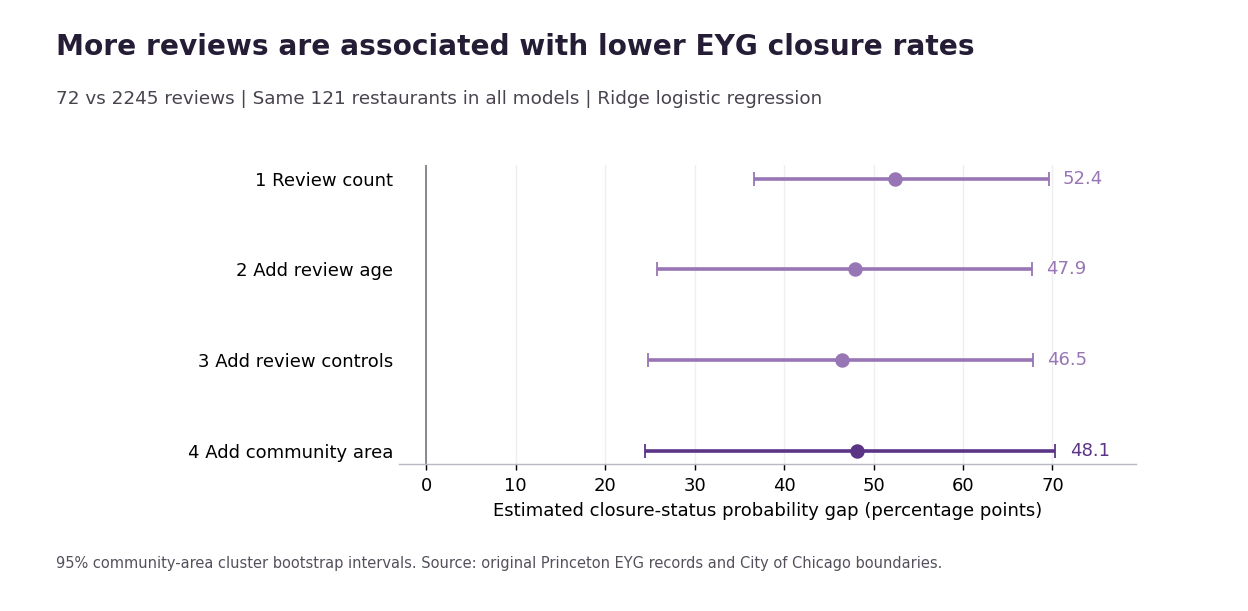

In [82]:
from io import BytesIO
import matplotlib.pyplot as plt
from IPython.display import Image

eyg_final = eyg_model_results.iloc[-1]
figure_title = "More reviews are associated with lower EYG closure rates"
eyg_plot_rows = eyg_model_results[["Model", "Gap (pp)", "Gap lower", "Gap upper"]].copy()
fig, ax = plt.subplots(figsize=(9.6, 4.7), dpi=160)
fig.subplots_adjust(left=0.32, right=0.91, top=0.73, bottom=0.24)
fig.text(0.045, 0.91, figure_title, fontsize=15.5, weight="bold", color="#251D35")
fig.text(
    0.045, 0.83, f"{eyg_low_count:g} vs {eyg_high_count:g} reviews | "
    f"Same {len(eyg_model_sample)} restaurants in all models | Ridge logistic regression",
    fontsize=10.2, color="#49434F",
)
for i, row in eyg_plot_rows.iterrows():
    color = "#5B3486" if i == 3 else "#9875B4"
    ax.errorbar(
        row["Gap (pp)"], i, fmt="o", markersize=7, linewidth=2, capsize=4, color=color,
        xerr=[[row["Gap (pp)"] - row["Gap lower"]], [row["Gap upper"] - row["Gap (pp)"]]],
    )
    ax.annotate(f"{row['Gap (pp)']:.1f}", (row["Gap upper"], i),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=10, color=color)
ax.set_yticks(range(4), eyg_plot_rows["Model"])
ax.invert_yaxis()
ax.set_xlim(min(0, eyg_plot_rows["Gap lower"].min()) - 3, eyg_plot_rows["Gap upper"].max() + 9)
ax.axvline(0, color="#77717C", linewidth=0.9)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines[["top", "left", "right"]].set_visible(False)
ax.spines["bottom"].set_color("#BCB8C1")
ax.set_xlabel("Estimated closure-status probability gap (percentage points)", fontsize=10)
fig.text(
    0.045, 0.07,
    "95% community-area cluster bootstrap intervals. Source: original Princeton EYG records and City of Chicago boundaries.",
    fontsize=8.1, color="#55505C",
)
eyg_figure_path = eyg_repo / "Checkpoint 5/eyg_review_volume_closure.png"
fig.savefig(eyg_figure_path, dpi=200)
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=130)
display(Image(data=buffer.getvalue()))
plt.close(fig)

eyg_output = eyg_repo / "person2_results"
eyg_output.mkdir(exist_ok=True)
eyg_model_results.to_csv(eyg_output / "eyg_model_comparison.csv", index=False)
eyg_sensitivity.to_csv(eyg_output / "eyg_model_sensitivity.csv", index=False)

### 8 Finding and narrative

The original EYG flags are verified for all 123 target restaurants, and all 91 overlaps agree with CHI. The raw median comparison uses all 123 records. The four adjusted models use 121 restaurants and retain all 32 closed cases. Two open-flag restaurants have no usable original review history for the age and negative-share controls.

Observed review age measures elapsed time since the first recorded review to the common reference date. It remains an approximation because actual opening and closure dates are unknown. Community-area coefficients are regularized, so these models provide a smaller-cohort comparison with a different estimator and fewer restaurant controls than Person 1's Google models.

In [83]:
eyg_final = eyg_model_results.iloc[-1]
eyg_raw_open_median = eyg_recovered.loc[
    ~eyg_recovered["eyg_is_closed"].astype(bool), "eyg_review_count"
].median()
eyg_raw_closed_median = eyg_recovered.loc[
    eyg_recovered["eyg_is_closed"].astype(bool), "eyg_review_count"
].median()
finding = (
    f"Among {len(eyg_model_sample)} EYG restaurants with complete records, "
    f"higher review volume was associated with lower odds of being marked closed "
    f"after accounting for observed review age, rating, negative-rating share, and community area "
    f"(regularized odds ratio per doubling {eyg_final['OR per doubling']:.2f}, "
    f"cluster-bootstrap 95% interval {eyg_final['OR lower']:.2f} to {eyg_final['OR upper']:.2f})."
)
narrative = (
    f"In the original EYG metadata, {eyg_effect['open_n']} open-flag restaurants had a median "
    f"of {eyg_raw_open_median:,.0f} reviews, compared with {eyg_raw_closed_median:,.0f} among "
    f"{eyg_effect['closed_n']} closed-flag restaurants. On the same {len(eyg_model_sample)} "
    f"complete restaurants, adding observed review age reduced the estimated low-versus-high "
    f"review-count closure-status gap from {eyg_model_results.iloc[0]['Gap (pp)']:.1f} to "
    f"{eyg_model_results.iloc[1]['Gap (pp)']:.1f} percentage points. With rating, negative-share, "
    f"and community-area controls, the fitted probabilities at {eyg_low_count:g} versus "
    f"{eyg_high_count:g} reviews were {eyg_final['Low reviews (%)']:.1f}% and "
    f"{eyg_final['High reviews (%)']:.1f}%, a {eyg_final['Gap (pp)']:.1f}-point gap "
    f"(cluster-bootstrap 95% interval {eyg_final['Gap lower']:.1f} to {eyg_final['Gap upper']:.1f}). "
    "The main adjusted result has the same direction as the Google finding, and its direction "
    "held under the penalty and leave-one-area-out checks. Actual operating duration remains "
    "unverified because review dates do not establish when a restaurant opened or closed. "
    "The historical selection, 32 closed cases, "
    "and uncertain status observation and closure dates limit this result to an exploratory "
    "association within the EYG cohort."
)
display(Markdown("**Adjusted finding.** " + finding + "\n\n**Narrative.** " + narrative))
(eyg_output / "eyg_adjusted_narrative.md").write_text(
    finding + "\n\n" + narrative + "\n", encoding="utf-8"
)
print("Handoff files saved in person2_results; model figure saved in Checkpoint 5.")

**Adjusted finding.** Among 121 EYG restaurants with complete records, higher review volume was associated with lower odds of being marked closed after accounting for observed review age, rating, negative-rating share, and community area (regularized odds ratio per doubling 0.60, cluster-bootstrap 95% interval 0.45 to 0.74).

**Narrative.** In the original EYG metadata, 91 open-flag restaurants had a median of 1,247 reviews, compared with 398 among 32 closed-flag restaurants. On the same 121 complete restaurants, adding observed review age reduced the estimated low-versus-high review-count closure-status gap from 52.4 to 47.9 percentage points. With rating, negative-share, and community-area controls, the fitted probabilities at 72 versus 2245 reviews were 59.3% and 11.1%, a 48.1-point gap (cluster-bootstrap 95% interval 24.5 to 70.3). The main adjusted result has the same direction as the Google finding, and its direction held under the penalty and leave-one-area-out checks. Actual operating duration remains unverified because review dates do not establish when a restaurant opened or closed. The historical selection, 32 closed cases, and uncertain status observation and closure dates limit this result to an exploratory association within the EYG cohort.

Handoff files saved in person2_results; model figure saved in Checkpoint 5.


### Analyses retained for the audit

The earlier pooled CHI/EYG/UDIS regressions describe a mixed cohort. They are retained above to document the investigation, and the original-source EYG models supply the current narrative.

The model checks include all-record versus complete-record baselines, alternate age references, penalty choices, and removal of each community area. A control based on the interval between the earliest and latest review was excluded because review-posting dates do not establish a restaurant's actual operating duration and can reflect experiences before posting. Category, chain status, and citywide competitor counts were omitted to keep the EYG model modest and avoid constructing a contemporary citywide census from this historical sample. Prospective prediction and survival analysis remain unsupported by the available opening and closure timing.